# Day 36 — Honest Scores
## Train/test split, cross-validation, and pipelines

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

There is **no new model** today.

Everything here applies just as much to the straight line from Day 33 as it does to
logistic regression, and to the trees and forests coming next week. Today is about one
question:

> **When you report a number, is it true?**

| Part | What we do |
|---|---|
| **1** | Why a score on the rows the model studied is not a score |
| **2** | Why one train/test split is a lottery |
| **3** | Cross-validation — give every row a turn |
| **4** | Leakage: the preparation step that spoils the measurement |
| **5** | Pipelines — one object that cannot be got wrong |

Run every cell. Several results in this notebook are deliberately surprising, and you
will not believe them unless you watch them happen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     LeaveOneOut, cross_val_score, cross_validate)
from sklearn.metrics import r2_score, accuracy_score, confusion_matrix

import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("ready")

ready


---
# Part 1 — Marking your own homework

## The data

120 students. Three things we know about each, and whether they passed.

120 rows is a realistic size for a class project or the first month of a new product.
It is also small enough that every problem in this notebook shows up clearly. On 200,000
rows most of them hide — which is exactly why people never learn them.

In [2]:
rng = np.random.default_rng(3601)
n = 120

hours      = rng.uniform(0, 20, n).round(1)
attendance = rng.uniform(40, 100, n).round(0)
prev_score = rng.normal(62, 14, n).clip(25, 98).round(0)

z = -7.0 + 0.22*hours + 0.035*attendance + 0.055*prev_score + rng.normal(0, 0.6, n)
passed = (rng.uniform(0, 1, n) < sigmoid(z)).astype(int)

students = pd.DataFrame({"hours": hours, "attendance": attendance,
                         "prev_score": prev_score, "passed": passed})

X = students[["hours", "attendance", "prev_score"]]
y = students["passed"]

print("rows:", len(students))
print("pass rate:", round(y.mean(), 4))
print("so 'everybody passes' is already right", f"{y.mean():.1%}", "of the time")
students.head()

rows: 120
pass rate: 0.75
so 'everybody passes' is already right 75.0% of the time


,hours,attendance,prev_score,passed
0,19.0,52.0,77.0,1
1,6.0,88.0,72.0,1
2,19.9,56.0,72.0,1
3,4.7,89.0,64.0,1
4,2.9,96.0,53.0,1


### Hold on to that 0.75

Before any model exists, there is already a score to beat: **guessing "passed" for
everybody gets 75% right.** Any accuracy we report has to be read against that number,
and we will come back to it in a moment.

## Five models, two scores each

We fit five models on the same 84 students, then ask each of them two questions:

1. How often are you right about **the students you studied**?
2. How often are you right about **the 36 students you have never seen**?

In [3]:
X_train, X_hidden, y_train, y_hidden = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(f"studied: {len(X_train)} students    hidden: {len(X_hidden)} students")
print()
print(f"{'model':<32}{'studied':>10}{'hidden':>10}{'gap':>10}")
print("-" * 62)

models = [("LogisticRegression",          LogisticRegression(max_iter=2000)),
          ("DecisionTree (no limit)",     DecisionTreeClassifier(random_state=0)),
          ("DecisionTree (max_depth=3)",  DecisionTreeClassifier(max_depth=3, random_state=0)),
          ("KNN  k=1",                    KNeighborsClassifier(1)),
          ("KNN  k=15",                   KNeighborsClassifier(15))]

for name, m in models:
    m.fit(X_train, y_train)
    a, b = m.score(X_train, y_train), m.score(X_hidden, y_hidden)
    print(f"{name:<32}{a:>10.4f}{b:>10.4f}{a-b:>+10.4f}")

print("-" * 62)
print(f"{'guessing passed for everybody':<32}{'':>10}{y_hidden.mean():>10.4f}")

studied: 84 students    hidden: 36 students

model                              studied    hidden       gap
--------------------------------------------------------------
LogisticRegression                  0.8571    0.7778   +0.0794
DecisionTree (no limit)             1.0000    0.6389   +0.3611
DecisionTree (max_depth=3)          0.9167    0.6111   +0.3056
KNN  k=1                            1.0000    0.6389   +0.3611
KNN  k=15                           0.7857    0.7500   +0.0357
--------------------------------------------------------------
guessing passed for everybody                 0.7500


### Read that table twice

**Read only the `studied` column** and the decision tree is the best model in the room —
a flawless **1.0000**.

**Read the `hidden` column** and it is the worst thing on the page. **0.6389** — below the
0.7500 you get from having no model at all.

The tree grew one branch for every student it was shown. Asked about those same students
it looks them up and is never wrong. Asked about anybody else it has nothing.

**This is the entire reason for holding rows back.** Without the second column there is
no way to tell the best model from the worst.

## What memorising actually looks like

`KNN k=1` asks: *who is my single closest classmate, and what happened to them?*
Every student is their own closest classmate, so it is trivially right about all of them.

`KNN k=15` asks fifteen classmates and takes a vote — so it is sometimes wrong about
students it has seen, on purpose.

Watch the shape of what each one learned.

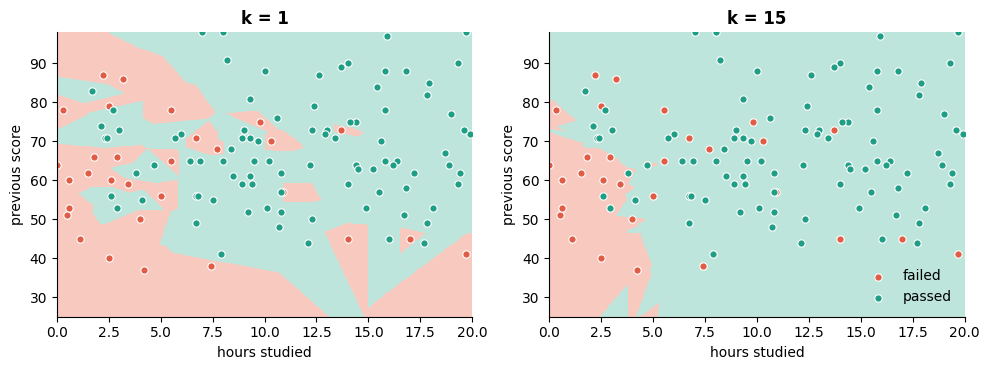

In [4]:
two = students[["hours", "prev_score"]].values
gx, gy = np.meshgrid(np.linspace(0, 20, 300), np.linspace(25, 98, 300))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, k in zip(axes, [1, 15]):
    mdl = make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(two, y)
    ax.contourf(gx, gy, mdl.predict(grid).reshape(gx.shape),
                levels=[-0.5, 0.5, 1.5], colors=["#F7C9BF", "#BEE5DB"])
    ax.scatter(two[y == 0, 0], two[y == 0, 1], s=28, c="#E05C45",
               edgecolor="white", lw=0.8, label="failed")
    ax.scatter(two[y == 1, 0], two[y == 1, 1], s=28, c="#1F9E86",
               edgecolor="white", lw=0.8, label="passed")
    ax.set_title(f"k = {k}", fontweight="bold")
    ax.set_xlabel("hours studied"); ax.set_ylabel("previous score")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

`k = 1` carved out a little island around every single student. That is not a pattern —
it is a stored copy of the data.

**Note the `StandardScaler` in there.** Without it, `prev_score` (which runs to 98) would
dominate the distance calculation and `hours` (which stops at 20) would barely count.
That is Day 32, and KNN is the model that cares about it most.

## The same thing in regression

Overfitting is not a classification problem. Here is a straight-line relationship with
noise on it, fitted with polynomials of rising degree.

Watch the two R² columns go in opposite directions.

In [5]:
r = np.random.default_rng(3605)
m_ = 40
xr = np.sort(r.uniform(0, 10, m_))
yr = 3 + 2.2*xr + r.normal(0, 2.8, m_)

xa, xb, ya, yb = train_test_split(xr.reshape(-1, 1), yr, test_size=0.35, random_state=1)
print(f"studied {len(xa)} points, held back {len(xb)}")
print()
print(f"{'degree':>8}{'studied R2':>13}{'held back R2':>15}")
print("-" * 36)
for d in [1, 2, 3, 5, 9, 14]:
    pl = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(xa, ya)
    print(f"{d:>8}{r2_score(ya, pl.predict(xa)):>13.4f}{r2_score(yb, pl.predict(xb)):>15.4f}")

studied 26 points, held back 14

  degree   studied R2   held back R2
------------------------------------
       1       0.7590         0.8319
       2       0.7598         0.8297
       3       0.8520         0.8001
       5       0.8749         0.7959
       9       0.9218         0.5571
      14       0.9253         0.1036


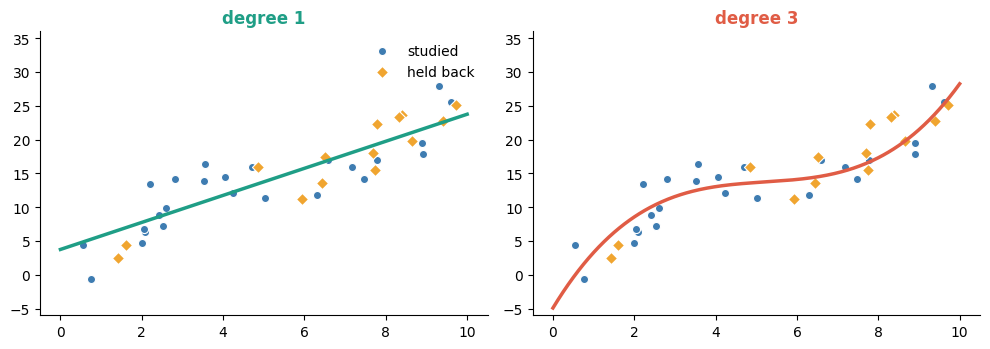

In [30]:
line = np.linspace(0, 10, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, d, c in zip(axes, [1, 3], ["#1F9E86", "#E05C45"]):
    pl = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(xa, ya)
    ax.scatter(xa, ya, s=34, c="#3E7CB1", edgecolor="white", lw=0.8, label="studied")
    ax.scatter(xb, yb, s=38, c="#F0A530", marker="D", edgecolor="white", lw=0.8,
               label="held back")
    ax.plot(line, pl.predict(line), color=c, lw=2.5)
    ax.set_ylim(-6, 36)
    ax.set_title(f"degree {d}", fontweight="bold", color=c)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

### The pattern to remember

**The studied score rose every single time.** 0.7590 → 0.9197. That is not evidence of
anything — adding flexibility *always* lets a model fit the rows in front of it better.

**The held-back score fell every single time.** 0.8319 → 0.5865.

Degree 14 did not find a better description of the data. It found a curve that passes
near every studied point, including the noise, and that curve is useless anywhere else.

> One small honest detail: at degree 1 the held-back R² (0.8319) is actually **higher**
> than the studied one (0.7590). That is not a mistake — the 14 held-back points happened
> to be an easier sample. Hold that thought; it is Part 2.

## Overfitting, in plain words

> **A model overfits when it has learned things that are true of the rows it studied and
> not true of anything else.**

| makes it more likely | how you detect it | what you do about it |
|---|---|---|
| a flexible model (deep tree, k=1, degree 14) | score the studied rows | a simpler model |
| few rows | score rows it never saw | more rows |
| many columns | look at the **gap** | fewer columns |
| noisy data | there is no other way | regularisation — a later day |

The middle column costs you nothing but discipline, and no amount of cleverness
substitutes for it.

---
# Part 2 — One split is a lottery

You have written this line at the top of every notebook since Day 32.

```python
X_train, X_hidden, y_train, y_hidden = train_test_split(
        X, y, test_size=0.3, random_state=0, stratify=y)
```

| argument | what it does | what happens without it |
|---|---|---|
| `test_size=0.3` | holds back 30% of the rows | defaults to 0.25 |
| `random_state=0` | makes the split repeatable | a different split every run |
| `stratify=y` | keeps the class mix the same on both sides | the mix drifts |
| `shuffle=True` | mixes the rows first (the default) | a sorted file splits into two worlds |

Three of those four exist to stop the split itself from lying to you. Here is why.

In [7]:
scores = []
for seed in range(20):
    a, b, c, d = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    scores.append(LogisticRegression(max_iter=2000).fit(a, c).score(b, d))
scores = np.array(scores)

for i in range(0, 20, 5):
    print("  " + "  ".join(f"{v:.4f}" for v in scores[i:i+5]))

print()
print(f"lowest  : {scores.min():.4f}   (random_state = {scores.argmin()})")
print(f"highest : {scores.max():.4f}   (random_state = {scores.argmax()})")
print(f"spread  : {scores.max() - scores.min():.4f}")
print(f"mean    : {scores.mean():.4f}    sd {scores.std(ddof=1):.4f}")

  0.7778  0.8056  0.8056  0.8333  0.8611
  0.7222  0.8056  0.8056  0.7500  0.8889
  0.8056  0.8611  0.8333  0.8333  0.8333
  0.8056  0.8333  0.8889  0.8333  0.8056

lowest  : 0.7222   (random_state = 5)
highest : 0.8889   (random_state = 9)
spread  : 0.1667
mean    : 0.8194    sd 0.0408


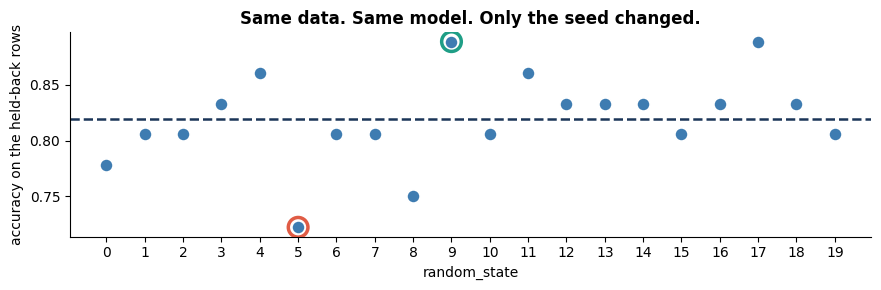

In [8]:
plt.figure(figsize=(9, 3))
plt.scatter(range(20), scores, s=90, c="#3E7CB1", edgecolor="white", lw=1.2, zorder=3)
plt.axhline(scores.mean(), color="#1B3558", ls="--", lw=1.8)
plt.scatter([scores.argmin()], [scores.min()], s=200, facecolor="none",
            edgecolor="#E05C45", lw=2.5, zorder=4)
plt.scatter([scores.argmax()], [scores.max()], s=200, facecolor="none",
            edgecolor="#1F9E86", lw=2.5, zorder=4)
plt.xticks(range(20)); plt.xlabel("random_state")
plt.ylabel("accuracy on the held-back rows")
plt.title("Same data. Same model. Only the seed changed.", fontweight="bold")
plt.tight_layout(); plt.show()

### Nothing changed between those twenty dots

Not one coefficient. Not one row of data. Not one character of code except the seed.

**16.7 points of swing**, purely from which 36 students happened to land in the held-back
pile.

### So which number do you report?

- **0.8889** — pick the best seed. This is how a great many published results happen,
  usually without anyone intending it: you try a few splits, one looks good, you stop.
- **0.7222** — pick the worst. Honest in spirit, but you are throwing away a model that
  is probably better than that.
- **0.8194** — the average of all twenty. Closest to the truth, and the idea behind
  everything in Part 3.

**The real problem is not which to pick.** It is that a single split hands you one number
and no idea how much to trust it. 0.8056 might mean "about 0.80" or "somewhere between
0.72 and 0.89", and one split cannot tell you which.

## Why 36 rows swing so hard

With 36 held-back rows, **one student is worth 1/36 = 0.0278** of the reported accuracy.
Six students' difference is the entire 16.7-point spread. Six, out of a hundred and
twenty.

And it is not only the exam that changes: each seed also hands the model a different 84
students to learn from. Both halves are rolling dice at once.

So what if we had more rows?

In [9]:
rng2 = np.random.default_rng(3610)
N = 2000
h2 = rng2.uniform(0, 20, N).round(1)
a2 = rng2.uniform(40, 100, N).round(0)
p2 = rng2.normal(62, 14, N).clip(25, 98).round(0)
z2 = -7.0 + 0.22*h2 + 0.035*a2 + 0.055*p2 + rng2.normal(0, 0.6, N)
y2 = (rng2.uniform(0, 1, N) < sigmoid(z2)).astype(int)
X2 = pd.DataFrame({"hours": h2, "attendance": a2, "prev_score": p2})

big = []
for seed in range(20):
    a, b, c, d = train_test_split(X2, y2, test_size=0.3, random_state=seed, stratify=y2)
    big.append(LogisticRegression(max_iter=2000).fit(a, c).score(b, d))
big = np.array(big)

print(f"{'':<14}{'lowest':>10}{'highest':>10}{'spread':>10}{'sd':>10}")
print(f"{'120 rows':<14}{scores.min():>10.4f}{scores.max():>10.4f}"
      f"{scores.max()-scores.min():>10.4f}{scores.std(ddof=1):>10.4f}")
print(f"{'2,000 rows':<14}{big.min():>10.4f}{big.max():>10.4f}"
      f"{big.max()-big.min():>10.4f}{big.std(ddof=1):>10.4f}")

                  lowest   highest    spread        sd
120 rows          0.7222    0.8889    0.1667    0.0408
2,000 rows        0.7467    0.7933    0.0467    0.0135


**The lottery shrinks with more rows** — 16.7 points down to 4.7.

More data is the only fix here that needs no new technique, and the one you usually
cannot have. Everything in Part 3 works with the rows you already own.

---
# Part 3 — Give every row a turn

If one exam is an unreliable measurement, sit five of them and average the marks.

That is **k-fold cross-validation**, and it is the whole idea. Split the rows into 5
groups. Five times over, hold one group back and train on the other four. Every row is
held back **exactly once** and studied four times.

Nothing is wasted, and no row is ever scored by a model that saw it.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
fold_scores = cross_val_score(LogisticRegression(max_iter=2000), X, y, cv=cv)

print("the five folds:", np.round(fold_scores, 4))
print()
print(f"mean               {fold_scores.mean():.4f}")
print(f"standard deviation {fold_scores.std(ddof=1):.4f}")
print()
print(f"report it as: about {fold_scores.mean():.2f}, "
      f"give or take about {fold_scores.std(ddof=1):.2f}")

the five folds: [0.875  0.8333 0.875  0.7917 0.75  ]

mean               0.8250
standard deviation 0.0543

report it as: about 0.82, give or take about 0.05


### Two things to notice about that code

**You pass all of `X` and all of `y`** — not `X_train`. Cross-validation does its own
splitting, five times over, and you must not have split the data yourself first.

**It fits five separate models and throws all five away.** What you keep is the five
numbers. The model you eventually ship gets fitted at the end, on everything.

### Never quote the mean on its own

The spread is half the result. If the five folds disagree wildly with each other, that
disagreement *is* the finding — it is telling you the measurement is unstable, which is
exactly what one split would have hidden.

## Is cross-validation actually more reliable? Measure it.

Part 2 showed twenty single splits ranging over 16.7 points. Let us run ten *whole
cross-validations*, each with a different shuffle, and see how much **they** disagree.

In [11]:
cv_means = []
for seed in range(10):
    cv_means.append(cross_val_score(
        LogisticRegression(max_iter=2000), X, y,
        cv=StratifiedKFold(5, shuffle=True, random_state=seed)).mean())
cv_means = np.array(cv_means)

print("ten cross-validations:", np.round(cv_means, 4))
print()
print(f"{'':<22}{'lowest':>10}{'highest':>10}{'spread':>10}")
print(f"{'20 single splits':<22}{scores.min():>10.4f}{scores.max():>10.4f}"
      f"{scores.max()-scores.min():>10.4f}")
print(f"{'10 cross-validations':<22}{cv_means.min():>10.4f}{cv_means.max():>10.4f}"
      f"{cv_means.max()-cv_means.min():>10.4f}")
print()
print(f"about {(scores.max()-scores.min())/(cv_means.max()-cv_means.min()):.1f}x tighter, "
      f"from exactly the same 120 rows")

ten cross-validations: [0.825  0.8167 0.8083 0.8083 0.8167 0.825  0.825  0.8    0.8417 0.8167]

                          lowest   highest    spread
20 single splits          0.7222    0.8889    0.1667
10 cross-validations      0.8000    0.8417    0.0417

about 4.0x tighter, from exactly the same 120 rows


## How many folds should you use?

More folds means more training data in each round, but fewer rows to score against.
Watch what that does to the spread.

In [12]:
print(f"{'cv':>14}{'mean':>10}{'sd':>10}{'fits':>7}{'rows held back':>17}")
print("-" * 58)
for label, cvo, k in [("3-fold",  StratifiedKFold(3, shuffle=True, random_state=0), 3),
                      ("5-fold",  StratifiedKFold(5, shuffle=True, random_state=0), 5),
                      ("10-fold", StratifiedKFold(10, shuffle=True, random_state=0), 10),
                      ("leave-one-out", LeaveOneOut(), 120)]:
    s_ = cross_val_score(LogisticRegression(max_iter=2000), X, y, cv=cvo)
    print(f"{label:>14}{s_.mean():>10.4f}{s_.std(ddof=1):>10.4f}{k:>7}{120/k:>17.1f}")

            cv      mean        sd   fits   rows held back
----------------------------------------------------------
        3-fold    0.8250    0.0433      3             40.0
        5-fold    0.8250    0.0543      5             24.0
       10-fold    0.8083    0.0966     10             12.0
 leave-one-out    0.8250    0.3816    120              1.0


### Use 5. Use 10 if you can afford the time.

10-fold holds back only 12 students per fold here, so each fold's score is noisier — and
you can see the standard deviation nearly double, from 0.0543 to 0.0966, even though the
mean barely moved.

### And now look at leave-one-out's ± 0.3816

In [13]:
loo = cross_val_score(LogisticRegression(max_iter=2000), X, y, cv=LeaveOneOut())

print("number of folds        :", len(loo))
print("the distinct fold scores:", sorted(set(loo.tolist())))
print()
print(f"got {int(loo.sum())} of {len(loo)} students right  ->  mean {loo.mean():.4f}")
print(f"'standard deviation'   : {loo.std(ddof=1):.4f}")
print()
p_ = loo.mean()
print(f"sd of ANY list of {len(loo)} zeros and ones with that mean: "
      f"{np.sqrt(p_*(1-p_)*len(loo)/(len(loo)-1)):.4f}")

number of folds        : 120
the distinct fold scores: [0.0, 1.0]

got 99 of 120 students right  ->  mean 0.8250
'standard deviation'   : 0.3816

sd of ANY list of 120 zeros and ones with that mean: 0.3816


### That ± is arithmetic, not uncertainty

Each leave-one-out fold trains on 119 students and is tested on **one**. So each fold's
"accuracy" is either 1.0 or 0.0 — there is no third possibility.

The standard deviation of a list of 0s and 1s is **fixed by the mean**. The last line
proves it: 0.3816 is what you get from *any* model that got 99 of 120 right, however
stable or unstable that model actually was.

**When leave-one-out is worth it:** when you have so few rows (under about 50) that
holding back 20% leaves nothing to test on. Even then, quote the mean and say nothing
about the spread.

## The disaster that happens to real files

Exports arrive sorted. By date, by customer, by region — or, as here, by the outcome
itself. The rows have not changed; only their order has.

In [14]:
srt = students.sort_values("passed").reset_index(drop=True)
Xs = srt[["hours", "attendance", "prev_score"]]
ys = srt["passed"]
print("first 12 values of 'passed':", ys.head(12).tolist())
print("last  12 values of 'passed':", ys.tail(12).tolist())
print()

for name, cvo in [("KFold(5), no shuffle",          KFold(5)),
                  ("KFold(5), shuffle=True",        KFold(5, shuffle=True, random_state=0)),
                  ("StratifiedKFold(5), shuffled",  StratifiedKFold(5, shuffle=True, random_state=0))]:
    rates = [ys.values[te].mean() for _, te in cvo.split(Xs, ys)]
    sc = cross_val_score(LogisticRegression(max_iter=2000), Xs, ys, cv=cvo)
    print(f"{name}")
    print(f"   pass rate inside each fold : {np.round(rates, 4)}")
    print(f"   accuracy on each fold      : {np.round(sc, 4)}")
    print(f"   reported                   : {sc.mean():.4f}")
    print()

first 12 values of 'passed': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
last  12 values of 'passed': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

KFold(5), no shuffle
   pass rate inside each fold : [0.   0.75 1.   1.   1.  ]
   accuracy on each fold      : [0.1667 0.8333 0.875  0.9167 0.9167]
   reported                   : 0.7417

KFold(5), shuffle=True
   pass rate inside each fold : [0.7083 0.7083 0.7083 0.75   0.875 ]
   accuracy on each fold      : [0.7917 0.7917 0.7917 0.875  0.875 ]
   reported                   : 0.8250

StratifiedKFold(5), shuffled
   pass rate inside each fold : [0.75 0.75 0.75 0.75 0.75]
   accuracy on each fold      : [0.8333 0.875  0.8333 0.9583 0.625 ]
   reported                   : 0.8250



### Fold 1 contained no passes at all

Its pass rate is **0.00**, so every student in it failed — and the model, which thinks
most people pass, scored **0.1250** on it. Folds 3, 4 and 5 are the mirror image: nothing
but passes.

The reported accuracy comes out **0.7333** instead of **0.8417**. Nothing was wrong with
the model. **The folds were built wrong**, and the only difference between the three runs
above is two keyword arguments.

### Which splitter, and when

| use this | when | why |
|---|---|---|
| `StratifiedKFold(shuffle=True)` | classification — almost always | keeps every fold's class mix matching the whole dataset |
| `KFold(shuffle=True)` | regression | no classes to balance, but shuffling is just as essential |
| `GroupKFold` | several rows belong to one person, patient or shop | keeps a whole group on one side, so the model cannot study a person and then be tested on them |
| `TimeSeriesSplit` | rows are in time order and you predict the future | always trains on the past and tests on the future — never shuffle time |

The last two exist because **"rows it never saw" has to mean genuinely never saw.** Two
hospital visits from the same patient are not two independent rows.

---
# Part 4 — The leak you cannot see

Here is a plan that sounds completely reasonable:

1. **Clean the data** — fill the gaps, scale the columns, keep the columns worth keeping
2. **Cross-validate** — 5-fold, stratified, shuffled, exactly as you just learned
3. **Report the mean** with its standard deviation

Every step is correct. **The order is wrong, and the order is everything.**

Step 1 looked at all the rows. By the time step 2 hides a fifth of them, the preparation
has already carried information out of the hidden rows and into the model.

This is called **leakage**. It does not throw an error. It does not look wrong. And it
makes your score better — which is why it survives review.

## A controlled experiment

200 patients. 5,000 columns of pure random numbers. The label is a **coin flip**.

There is nothing to predict here. There *cannot* be. An honest score must be about 0.50.

In [15]:
rng = np.random.default_rng(3620)
n_, p_ = 200, 5000
Xn = rng.normal(0, 1, (n_, p_))
yn = rng.integers(0, 2, n_)          # coin flips

print("rows:", n_, "  columns:", p_, "  positive rate:", round(yn.mean(), 4))
print("the labels have NOTHING to do with the columns.")

rows: 200   columns: 5000   positive rate: 0.5
the labels have NOTHING to do with the columns.


In [16]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# ---- WRONG: pick the best 20 columns using every row, then cross-validate
chosen = SelectKBest(f_classif, k=20).fit(Xn, yn)
wrong = cross_val_score(LogisticRegression(max_iter=2000), chosen.transform(Xn), yn, cv=cv)

# ---- RIGHT: let the selection happen inside each fold
pipe = Pipeline([("select", SelectKBest(f_classif, k=20)),
                 ("model",  LogisticRegression(max_iter=2000))])
right = cross_val_score(pipe, Xn, yn, cv=cv)

print(f"select first, then CV   folds {np.round(wrong, 4)}   mean {wrong.mean():.4f}")
print(f"selection in the Pipeline folds {np.round(right, 4)}   mean {right.mean():.4f}")
print()
print(f"the leak is worth {wrong.mean() - right.mean():+.4f} of pure fiction")

select first, then CV   folds [0.775 0.85  0.8   0.825 0.825]   mean 0.8150
selection in the Pipeline folds [0.6   0.55  0.5   0.575 0.475]   mean 0.5400

the leak is worth +0.2750 of pure fiction


### 0.8150 — on coin flips

Here is how that number is manufactured:

1. With 5,000 random columns, **some will line up with the coin flips by chance**
2. `SelectKBest` finds the 20 that line up best — using **all 200 rows, labels included**
3. Cross-validation then hides 40 rows — but those 40 helped choose the columns
4. So the model is scored on rows that the columns were picked to fit

The Pipeline version chooses its 20 columns again inside each fold, from that fold's 160
training rows only. The columns that happened to fit the 40 hidden rows are no longer in
the running, the fiction evaporates, and the score drops to 0.5400.

> 0.5400 is not exactly 0.5000 either. With five folds of 40 rows that is ordinary noise,
> and the honest reading is still "this data predicts nothing".

**If you only ever remember one thing from today, make it this slide's number.**

## But does *every* step leak? No. Measure it.

It would be easy to tell you that everything leaks and you should be terrified. That
would be false, and once you discovered it was false you would stop believing any of it.

So here are three more steps, measured the same way.

In [17]:
# ---- scaling ----------------------------------------------------------
r2 = np.random.default_rng(3621); N_ = 300
f1 = r2.normal(50, 15, N_); f2 = r2.normal(0, 1, N_)*200; f3 = r2.uniform(0, 5, N_)
zz = -2.0 + 0.03*f1 + 0.004*f2 + 0.5*f3 + r2.normal(0, 0.5, N_)
yy = (r2.uniform(0, 1, N_) < sigmoid(zz)).astype(int)
XX = np.c_[f1, f2, f3]

w = cross_val_score(LogisticRegression(max_iter=2000),
                    StandardScaler().fit_transform(XX), yy, cv=cv)
rgt = cross_val_score(Pipeline([("sc", StandardScaler()),
                                ("lr", LogisticRegression(max_iter=2000))]), XX, yy, cv=cv)
print(f"scale first, then CV : {w.mean():.4f}")
print(f"scale inside the CV  : {rgt.mean():.4f}")
print(f"the leak             : {w.mean() - rgt.mean():+.4f}")

scale first, then CV : 0.6533
scale inside the CV  : 0.6533
the leak             : +0.0000


In [18]:
# ---- filling the gaps -------------------------------------------------
r3 = np.random.default_rng(3622); M_ = 300
g1 = r3.normal(50, 15, M_); g2 = r3.normal(30, 8, M_)
z3 = -4.0 + 0.05*g1 + 0.06*g2 + r3.normal(0, 0.5, M_)
y3 = (r3.uniform(0, 1, M_) < sigmoid(z3)).astype(int)
G = np.c_[g1, g2].copy()
G[r3.uniform(0, 1, (M_, 2)) < 0.30] = np.nan
print("missing cells:", int(np.isnan(G).sum()), "of", G.size)

w3 = cross_val_score(LogisticRegression(max_iter=2000),
                     SimpleImputer().fit_transform(G), y3, cv=cv)
r3_ = cross_val_score(Pipeline([("im", SimpleImputer()),
                                ("lr", LogisticRegression(max_iter=2000))]), G, y3, cv=cv)
print(f"impute first, then CV: {w3.mean():.4f}")
print(f"impute inside the CV : {r3_.mean():.4f}")
print(f"the leak             : {w3.mean() - r3_.mean():+.4f}")

missing cells: 179 of 600
impute first, then CV: 0.5767
impute inside the CV : 0.5833
the leak             : -0.0067


### Four steps, four very different answers

| the step done before splitting | does it look at `y`? | what the leak was worth |
|---|---|---|
| scale the columns | no | **+0.0000** |
| fill the gaps with the mean | no | **−0.0067** |
| pick the best 20 of 5,000 columns | **yes** | **+0.2750** |
| pick the best 8 of 60, strong signal | **yes** | **+0.0000** (see below) |

## The rule

> **A step that never looks at `y` leaks almost nothing.
> A step that makes a choice using `y` can leak everything.**

| never looks at `y` | chooses using `y` |
|---|---|
| `StandardScaler`, `SimpleImputer`, `OneHotEncoder`, `PolynomialFeatures` | `SelectKBest`, `RFE`, "drop the columns that don't correlate with the target" |
| adding 20% more rows barely moves a mean or a standard deviation | the choice is itself part of the model, and it was made using the answers |

Note the second row on the right includes **tuning any setting**. Choosing `max_depth` by
trying values and keeping the best is a choice made using `y` — which is why
hyperparameter tuning gets its own day, and its own extra split.

## And the leak is only as big as the choice is unstable

Why did the last row of that table leak **zero**? Let us measure the thing that actually
drives it: **how much does the chosen set of columns change from fold to fold?**

In [19]:
print(f"{'case':<28}{'overlap':>10}{'leaked':>10}{'honest':>9}{'leak':>9}")
print("-" * 66)
for tag, seed_, N_, P_, strength, k_ in [
        ("5,000 cols, no signal",  3620, 200, 5000, 0.0,  20),
        ("60 cols, weak signal",   3630, 250, 60,   0.25, 8),
        ("60 cols, strong signal", 3630, 250, 60,   1.0,  8)]:
    rr = np.random.default_rng(seed_)
    Xr = rr.normal(0, 1, (N_, P_))
    if strength > 0:
        zl = strength*(0.9*Xr[:,0] + 0.7*Xr[:,1] - 0.6*Xr[:,2] + 0.5*Xr[:,3]) \
             + rr.normal(0, 0.6, N_)
        yrr = (rr.uniform(0, 1, N_) < sigmoid(zl)).astype(int)
    else:
        yrr = rr.integers(0, 2, N_)

    picks = [set(np.where(SelectKBest(f_classif, k=k_).fit(Xr[tr], yrr[tr]).get_support())[0])
             for tr, _ in cv.split(Xr, yrr)]
    overlap = np.mean([len(picks[i] & picks[j])/k_ for i in range(5) for j in range(i+1, 5)])

    sel = SelectKBest(f_classif, k=k_).fit(Xr, yrr)
    lk = cross_val_score(LogisticRegression(max_iter=2000), sel.transform(Xr), yrr, cv=cv).mean()
    hn = cross_val_score(Pipeline([("s", SelectKBest(f_classif, k=k_)),
                                   ("l", LogisticRegression(max_iter=2000))]),
                         Xr, yrr, cv=cv).mean()
    print(f"{tag:<28}{overlap:>10.2%}{lk:>10.4f}{hn:>9.4f}{lk-hn:>+9.4f}")

case                           overlap    leaked   honest     leak
------------------------------------------------------------------
5,000 cols, no signal           25.00%    0.8150   0.5400  +0.2750
60 cols, weak signal            41.25%    0.6000   0.5400  +0.0600
60 cols, strong signal          57.50%    0.7440   0.7440  +0.0000


### The leak is exactly as large as the instability of the choice

When the signal is strong, `SelectKBest` picks essentially the same columns in every
fold — so choosing once on everything gives the model nothing it would not have found
anyway, and the leak is **zero**.

When there is no signal, the "best" columns are different every time, and choosing once
on everything hands the model a set tuned to the very rows it is about to be scored on.

**The danger lives exactly where the evidence is weakest** — which is the worst possible
place for a safety rule to fail, and the reason not to rely on judging each case.

---
# Part 5 — One object, no leaks

You could reason it out every time: does this step look at `y`, is the choice stable, how
many rows do I have.

Or you could put every step inside **one object that refits all of them in every fold**,
and stop thinking about it.

```python
pipe = Pipeline([("scale", StandardScaler()),
                 ("model", LogisticRegression(max_iter=2000))])

pipe.fit(X_train, y_train)    # fits BOTH steps
pipe.predict(X_new)           # scales X_new, then predicts
```

Three properties make it work:

1. **It has `.fit` and `.predict`** — so anywhere a model goes, a pipeline goes, including
   straight into `cross_val_score`
2. **Transformers are fitted on train only**, then applied to whatever comes next using
   the numbers learned from train
3. **Order is guaranteed** — you cannot forget the scaler on new data

## Real data: number columns and word columns

900 loan applications. Three number columns, two word columns, and 8% of the incomes
missing.

- the **numbers** need their gaps filled, then scaling
- the **words** need one-hot encoding

`ColumnTransformer` sends each group down its own route and glues the results together.

In [20]:
r5 = np.random.default_rng(3640)
M = 900

age    = r5.normal(34, 9, M).clip(19, 65).round(0)
income = r5.normal(58, 24, M).clip(12, 180).round(1)
score  = r5.normal(640, 70, M).clip(400, 850).round(0)
city   = r5.choice(["metro", "tier2", "tier3"], M, p=[.45, .35, .20])
job    = r5.choice(["salaried", "self_employed"], M, p=[.68, .32])

cb = np.where(city == "metro", 0.35, np.where(city == "tier2", 0.0, -0.40))
jb = np.where(job == "salaried", 0.30, -0.30)
z = (-22.5 + 4.5*(0.018*age + 0.016*income + 0.0055*score)
     + 2.2*(cb + jb) + r5.normal(0, 0.45, M))
approved = (r5.uniform(0, 1, M) < sigmoid(z)).astype(int)

loans = pd.DataFrame({"age": age, "income": income, "credit_score": score,
                      "city": city, "job_type": job, "approved": approved})
loans.loc[r5.uniform(0, 1, M) < 0.08, "income"] = np.nan

print("rows:", len(loans))
print("approval rate:", round(loans.approved.mean(), 4),
      " -> baseline to beat:", round(max(loans.approved.mean(),
                                         1 - loans.approved.mean()), 4))
print("missing incomes:", int(loans.income.isna().sum()))
loans.head()

rows: 900
approval rate: 0.6144  -> baseline to beat: 0.6144
missing incomes: 76


,age,income,credit_score,city,job_type,approved
0,32.0,41.2,719.0,tier2,salaried,0
1,34.0,85.8,637.0,tier2,salaried,1
2,38.0,18.4,585.0,metro,salaried,0
3,30.0,65.9,563.0,metro,self_employed,0
4,21.0,37.3,748.0,tier3,self_employed,0


In [21]:
num = ["age", "income", "credit_score"]
cat = ["city", "job_type"]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num),
    ("cat", OneHotEncoder(drop="first"), cat)])

full = Pipeline([("prep",  prep),
                 ("model", LogisticRegression(max_iter=2000))])

Xl = loans[num + cat]
yl = loans.approved

res = cross_validate(full, Xl, yl, cv=cv, return_train_score=True)
print("fold scores (held back):", np.round(res["test_score"], 4))
print("fold scores (studied)  :", np.round(res["train_score"], 4))
print()
print(f"held back  {res['test_score'].mean():.4f}  sd {res['test_score'].std(ddof=1):.4f}")
print(f"studied    {res['train_score'].mean():.4f}")
print(f"the gap    {res['train_score'].mean() - res['test_score'].mean():.4f}")
print(f"baseline   {max(yl.mean(), 1-yl.mean()):.4f}")

fold scores (held back): [0.8111 0.8167 0.8222 0.7778 0.7944]
fold scores (studied)  : [0.8111 0.8056 0.7972 0.8153 0.8097]

held back  0.8044  sd 0.0182
studied    0.8078
the gap    0.0033
baseline   0.6144


### Read that last block

**That one `cross_validate` call fitted the imputer, the scaler, the encoder and the
model five separate times**, each on four-fifths of the data. You wrote none of that loop.

**0.8044 against a baseline of 0.6144** — a gain of 19 points.

**The gap between studied and held back is 0.0033.** This model is not overfitting — and
that sentence only means something because of everything in Parts 1 to 4.

In [22]:
full.fit(Xl, yl)
names = full.named_steps["prep"].get_feature_names_out()
coefs = full.named_steps["model"].coef_[0]

print("the columns the pipeline built:")
for nm, c in zip(names, coefs):
    print(f"   {nm:<30}{c:>+8.4f}   odds x {np.exp(c):.3f}")
print(f"   {'intercept':<30}{full.named_steps['model'].intercept_[0]:>+8.4f}")
print()
print("median income it learned, for filling the gaps:",
      full.named_steps["prep"].named_transformers_["num"].named_steps["imp"].statistics_[1])

the columns the pipeline built:
   num__age                       +0.5598   odds x 1.750
   num__income                    +1.4599   odds x 4.306
   num__credit_score              +1.4129   odds x 4.108
   cat__city_tier2                -0.7515   odds x 0.472
   cat__city_tier3                -1.4438   odds x 0.236
   cat__job_type_self_employed    -0.9388   odds x 0.391
   intercept                      +1.6118

median income it learned, for filling the gaps: 57.9


Two columns became six, the gaps were filled with a median the pipeline worked out for
itself, and because the numbers were scaled, **these coefficients are directly
comparable** — income (+1.46) and credit score (+1.41) do most of the work, and being
self-employed costs you (−0.94), as does living in a tier-3 city (−1.44).

That is Day 34's scaled-coefficient lesson, arriving for free.

## Does the Pipeline actually change the score here?

Let us do it the wrong way on purpose — fill and scale everything up front, then
cross-validate — and compare.

In [23]:
Xw = Xl.copy()
Xw["income"] = Xw["income"].fillna(Xw["income"].median())
Xw = pd.get_dummies(Xw, columns=cat, drop_first=True).astype(float)
Xw[num] = StandardScaler().fit_transform(Xw[num])

wrong_way = cross_val_score(LogisticRegression(max_iter=2000), Xw, yl, cv=cv)
print("by hand, prepared up front:", np.round(wrong_way, 4), f" mean {wrong_way.mean():.4f}")
print("inside the Pipeline       :", np.round(res['test_score'], 4),
      f" mean {res['test_score'].mean():.4f}")
print()
print(f"difference: {wrong_way.mean() - res['test_score'].mean():+.4f}")

by hand, prepared up front: [0.8111 0.8167 0.8222 0.7778 0.7944]  mean 0.8044
inside the Pipeline       : [0.8111 0.8167 0.8222 0.7778 0.7944]  mean 0.8044

difference: +0.0000


### Identical. So why bother?

I could have hidden this result and told you pipelines protect your score. Sometimes they
do — Part 4 is proof. Here they did not, because neither scaling nor median-filling looks
at `y`.

**The real reasons are these:**

| | |
|---|---|
| **You cannot forget a step** | new rows get the same median, the same scaling, the same column order — automatically |
| **Cross-validation becomes safe** | every step is refitted inside each fold, without you deciding which ones needed it |
| **One object to save** | the whole thing, not six separate pieces to reassemble |

Correctness stops depending on you remembering.

## Fit it once, save it, use it tomorrow

```python
import joblib

full.fit(X, y)                        # now fit on every row you have
joblib.dump(full, "loan_model.joblib")

# next week, in a completely different program:
model = joblib.load("loan_model.joblib")
model.predict_proba(new_applications)[:, 1]
```

**Why fit on everything at the end?** Cross-validation was the *measurement* — it told you
to expect about 0.80. The five models it built have done their job and are gone. The model
you ship is fitted on all 900 rows.

**What goes in that file:** the median income used for filling (57.9), every column's mean
and standard deviation, the category list, the column order, and the coefficients. Save
the model alone and every one of those is lost.

> A model on its own is not deployable. A pipeline is.

## So do you still need a separate test set?

**If you only fit** — one model, no choices made from the scores — cross-validation alone
is honest, and its mean is a fair estimate.

**If you also choose** — trying five models, or ten values of `max_depth`, and keeping the
best CV score — that is a choice made using `y`, and Part 4 applies to it.

```
all your rows
    -> 80% working set   cross-validate inside here as much as you like
    -> 20% final test    opened once, at the very end
```

**Best of twenty is not an average of twenty.** If you pick the highest of twenty
cross-validated scores, that winner is high partly on merit and partly on luck, and only
rows that nothing has touched can tell you how much of each.

You are fitting only, for now, so cross-validation alone is honest. Keep this for the
tuning day, when you start choosing.

---
# The four habits

| | | |
|---|---|---|
| **1** | **Hold rows back** | never score a model on rows it studied |
| **2** | **Use folds** | one split on 120 rows swung 16.7 points |
| **3** | **Shuffle and stratify** | a sorted file gave one fold with no passes in it |
| **4** | **Use a Pipeline** | so no fold ever sees the rows it will score |

Not one of these makes the model better. They are about knowing whether it is.

## Mistakes this notebook should stop you making

| if you catch yourself... | what is wrong | do this instead |
|---|---|---|
| reporting `.score(X_train, y_train)` | that is the studied rows | score the held-back rows, or cross-validate |
| trying seeds until one looks good | you are picking the lottery ticket | cross-validate, report mean ± sd |
| scaling before `train_test_split` | harmless here, a bad habit elsewhere | put the scaler in a Pipeline |
| picking columns before cross-validating | the leak worth 27.5 points | put the selector in the Pipeline |
| `KFold` on a file you did not shuffle | a fold with no positives in it | `StratifiedKFold(shuffle=True)` |
| quoting a mean with no spread | half the result is missing | always quote both |

**Every one of these makes your number go up.** That is what makes them hard to catch —
nobody ever double-checks a disappointing result.

## Five numbers from today

- **1.0000** — a decision tree on the rows it studied, and **0.6389** on rows it had not,
  below the **0.7500** you get by guessing
- **16.7 points** — the spread across twenty splits of the same 120 students
- **0.1250** — what one fold scored when the file arrived sorted and nobody passed `shuffle`
- **0.8150** — accuracy on labels that were literally coin flips
- **0.0000** — the leak from scaling before splitting; not every warning you read online
  is worth the same

---

**Tomorrow:** evaluation metrics for classification — what to measure, now that you know
how to measure it honestly.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*